 #  <center> <span style = "color:darkblue;font-weight:bold;font-size:1.1em">  Project </span>  </center>

For this project, you'll be analyzing real data provided by professors and their research students in chemistry and biology.  Here's the story:

Chemistry students synthesized three different derivatives of penicillin, and meanwhile other students in a microbiology class grew two different bacteria in petri dishes.  The synthesized derivatives of penicillin are supposed to possess antibacterial qualities, which is to say they act as antibiotics.  To test those qualities, the three derivatives were introduced into the petri dishes, by soaking a small disk of paper in the antibiotic then placing the disk in the petri dish.  The "zone of inhibition" is the circular region around the disk where the bacteria was not able to grow.  (This is also known as a Kirby-Bauer test.)  The diameters of these zones of inhibition were measured in decimeters and recorded, the data is available below.  The larger the zone of inhibition the more effective the antibiotic.    

- Of the two bacteria, was one of the derivatives more effective than penicillin?  Or ampicillin?

- Was the 5 parts per million or the 10 parts per million more effective?  (Parts per million will be abbreviated to ppm.)

- Was any derivative more effective against the gram positive bacteria (*S. epidermidis*) or the the gram negative bacteria (*E. coli*)?

- If one compound is effective against *E. coli* is it likely to be effective against *S. epidermidis*?

In [4]:
## This cell imports modules and functions used in the rest of the notebook

from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
import seaborn as sns
import scipy.stats as stats
from scipy.stats import gaussian_kde

penicillin = Table.read_table("Penicillin measurements.csv")
penicillin = penicillin.relabel(1, "E. coli").relabel(2, "S. epidermidis").relabel(0,"Compound")

In [5]:
def describe(data, var = None):
  if isinstance(data, Table):
    data = data.column(var)
  names = np.array(["mean", "std", "n", " : : ", "min", "Q1", "median", "Q3", "max", "IQR"])
  values = np.array([round(np.mean(data),1), round(stats.tstd(data),2), len(data) - 1, "", min(data), np.percentile(data, 25), np.median(data), np.percentile(data, 75), max(data), stats.iqr(data)])
  tab = Table().with_columns('Names', names, 'Values', values)  ;  transposed_tab = Table().with_columns( zip(tab.column('Names'), tab.column('Values')) ).show()
  return

def describes(data, num, group):
  dat = data.column(num)  ;  group_var = data.column(group)  ;  groups = np.unique(group_var)  ;  rows = []  ;  tab = Table(["mean", "std", "n", " : : ", "min", "Q1", "median", "Q3", "max", "IQR"])
  for g in groups:
    # Filter data for the current group
    sub_dat = dat[group_var == g]  ;    rows = [g, round(np.mean(sub_dat), 1), round(stats.tstd(sub_dat), 2), len(sub_dat) - 1, min(sub_dat), np.percentile(sub_dat, 25), np.median(sub_dat), np.percentile(sub_dat, 75), max(sub_dat), stats.iqr(sub_dat)]        
    tab = tab.with_row(rows)
  tab.show()
  return 

def box(data, num = None, sm = False):
  if isinstance(data, Table):
    df = data.to_df()  ;  sns.boxplot(data=df, y=num, width=0.45, showmeans=sm)  ;
    plots.title(f'Boxplot of {num}')  ;  plots.xticks([], [])  ;  plots.show()  
  else:
    if num == True:
      sm = True  ;  num = 'Variable'
    if num == None:
      num = 'Variable'
    plots.figure(figsize=(6, 6))  ;  plots.boxplot(data, widths = 0.45, showmeans=sm)
    plots.title(f'Boxplot of {num}')  ;  plots.xticks([], [])  ;  plots.show()
  return

def boxes(data, num, cat, sm = False):
  if not isinstance(data, Table):
    print("ERROR: First input must be table name.")
  else:
    df = data.to_df()  ;  sns.boxplot(data=data, x=cat, y=num, width=0.75, showmeans=sm)
    plots.title(f'Boxplot of {num} Grouped by {cat}')  ;  plots.show()
  return

def density(data, num = None):
  if isinstance(data, Table):
    sns.kdeplot( data = data.column(num), bw_method="scott", bw_adjust=0.75, cut=3 )  ;  plots.title(f'Density Plot of {num}')  ;  plots.show()
  else:
    if num == None:
      num = 'Variable'  ;  sns.kdeplot( data = data, bw_method="scott", bw_adjust=0.75, cut=3 )  ;  plots.title(f'Density Plot of {num}')  ;  plots.show()
    else:
      sns.kdeplot( data = data, bw_method="scott", bw_adjust=0.75, cut=3 )  ;  plots.title(f'Density Plot of {num}')  ;  plots.show()
  return

def densities(tab, var, group_var):
  groups = tab.column(group_var) ;  unique_groups = np.unique(groups)  ;  plots.figure()
  for g in unique_groups:
    # Filter data for the current group
    mask = (groups == g)
    x = tab.column(var)[mask]   
    # Calculate KDE for the group subset
    kde = gaussian_kde(x)
    x_grid = np.linspace(x.min() - 1, x.max() + 1, 512)  ;    plots.plot(x_grid, kde(x_grid), label=str(g))   
  plots.title(f'Density Plot of {var} by {group_var}')  ;  plots.xlabel(f'{var}')  ;  plots.ylabel('Density')
  plots.legend()  ;  plots.show()
  return

In [6]:
## To see a sample of the data, run this cell, otherwise skip it.
penicillin.take(make_array(0,2,12,19,25,28,32,37,45))

## To see all the data take the # off the line below
#penicillin.show()

Compound,E. coli,S. epidermidis
Ampicillin,15,34
Penicillin,11,33
Water,12,0
ER (green) 5ppm,0,9
ER (yellow) 10 ppm,11,12
AG (light blue) 5 ppm,0,26
AG (purple) 10 ppm,0,0
JH (red) 5 ppm,28,55
JH (orange) 10 ppm,20,49


## First Research Question

Against *E. coli*, was one of the derivatives more effective than penicillin? Or ampicillin?

### 1.1
In the cell below, use the `describes` function to find the summary statistics for the numeric variable **E. coli** split by grouping variable **Compound**.

In [7]:
...

Ellipsis

In [8]:
## The next few lines prepares the data for an ANOVA ##
## column 1 is the E. coli column.

E_ag5 = penicillin.where("Compound", "AG (light blue) 5 ppm").column(1)
E_ag10 = penicillin.where("Compound", "AG (purple) 10 ppm").column(1)
E_ampic = penicillin.where("Compound", "Ampicillin").column(1)
E_er5 = penicillin.where("Compound", "ER (green) 5ppm").column(1)
E_er10 = penicillin.where("Compound", "ER (yellow) 10 ppm").column(1)
E_jh5 = penicillin.where("Compound", "JH (red) 5 ppm").column(1)
E_jh10 = penicillin.where("Compound", "JH (orange) 10 ppm").column(1)
E_penic = penicillin.where("Compound", "Penicillin").column(1)
E_h2o = penicillin.where("Compound", "Water").column(1)

## The next line actually runs the ANOVA ##
stats.f_oneway(E_ag5, E_ag10, E_ampic, E_er5, E_er10, E_jh5, E_jh10, E_penic, E_h2o)

F_onewayResult(statistic=21.988721506226131, pvalue=7.3693238241202118e-13)

### 1.2 
In the cell above, a one-way ANOVA test was run.  The null and alternative hypotheses for a such an ANOVA are as follows:

$ H_o: $ *All groups have the same mean*
    
$ H_a: $ *At least one group has a different mean*
        
Which interpretation of the results is correct?


a) The p-value is small, so all the means are approximately the same.

b) The p-value is large, so all the means are approximately the same.

c) The p-value is small, so at least one group mean is different.

d) The p-value is large, so at least one group mean is different.  

*Replace this text with your response.*

### 1.3
In the cell below, a set of side-by-side boxplots is prepared. Remembering, that higher is better for this measurement, which derivative was most effective?  Just based on the graph, does it appear to be more effective than penicillin and/or ampicillin?

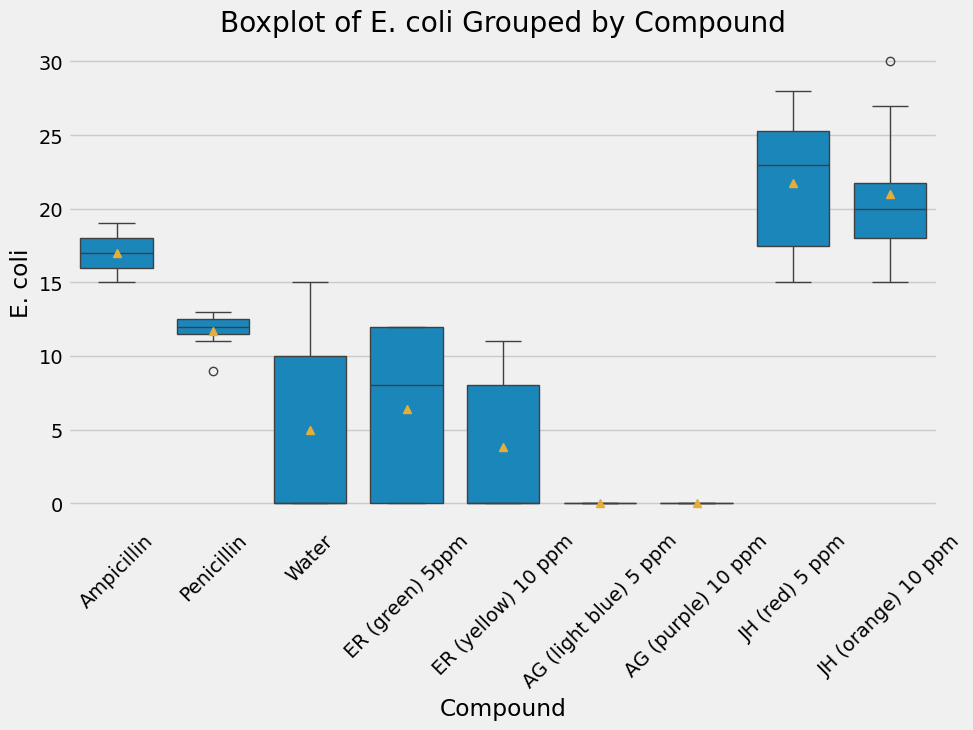

In [16]:
plots.figure( figsize = (10,6) )
plots.xticks(rotation=45)
boxes(penicillin, 'E. coli', 'Compound', True)

*Replace this text with your answer.*

**1.4** Run a two-sample t-test to compare the array named `E_jh5` to the array called `E_penic`.  Then interpret the results in the cell below that.  

*Replace this text with your interpretation of the results of your t-test*

**1.5** Run a two-sample t-test to compare the array named `E_jh5` to the array called `E_ampic`.  Then interpret the results in the cell below that.  

*Replace this text with your interpretation of the results of your t-test*

## Second Research Question

Against *S. epidermidis*, was one of the derivatives more effective than penicillin? Or ampicillin?

In the cell, below the data has been prepared for you but, this time you'll have to perform all the analyses without as much guidance.  Repeat the processes and analyses that were performed for the First Research Question in the empty cells below.  Include appropriate grapics and state your conclusions.  You should be able to accomplish all of this by copying, pasting and editing the cells above.

**2.1** Using the dataset called penicillin2, create the variables you'll need.  Use the variable names provided in the cell below.  If you choose to use other variable names, instructions given to you later in this project may be confusing.  

**2.2** Use the `groupstats` function to get a summary of this data split by "Compound" for "S. epidermidis".

**2.3** Run the one-way ANOVA using these new variables.  

**2.4** Make the box-plots that allow for visual comparison between these groups.  

**2.5** For the most effective derivative/concentration, run two-sample t-tests comparing that group to penicillin.

**2.6** For the most effective derivative/concentration, run two-sample t-tests comparing that group to ampicillin. 

For all of these parts, be sure to include a brief interpretation of your results.  

In [17]:
## These next few lines prepare the data that you'll need for this section and those that follow.
## Don't change these lines

penicillin2 = penicillin.where("S. epidermidis", are.above(-1))

## Do 2.1 in the rest of this cell 

S_ag5 = ...
S_ag10 = ...
S_ampic = ...
S_er5 = ...
S_er10 = ...
S_jh5 = ...
S_jh10 = ...
S_penic = ...
S_h2o = ...

In [25]:
## Do 2.2 in the rest of this cell 



In [26]:
## Do 2.3 in the rest of this cell 



In [27]:
## Do 2.4 in the rest of this cell 



In [28]:
## Do 2.5 in the rest of this cell 



In [29]:
## Do 2.6 in the rest of this cell 



## Third Research Question

By now, you've observed that the JH compound was more effective against both *E. coli* and *S. epidermidis*.  Did the concentration of this compound matter?

**3.1** For just *E. coli*, was there a significant difference between `E_jh5` and `E_jh10`?  Run a two-sample t-test in the cell below and interpret the results.  

**Hypothesis**

- $H_0 : \mu_5 = \mu_{10}$
- $H_a : \mu_5 \neq \mu_{10}$

In [21]:
...

Ellipsis

*Replace this text with your response*

**3.2** Repeat the analysis in the previous part, but this time use the *S. epidermidis* data, `S_jh5` and `S_jh10`.

*Replace this text with your response*

## Fourth Research Question ##

**4.1** Using the data called `E_jh5`, and `S_jh5` test whether the 5 ppm concentration of the JH compound was more effective against *E. coli* or *S. epidermidis*.

In [30]:
#ticks = make_array(1,2)
#labels = make_array("E_jh5", "S_jh5")

#plots.boxplot(E_jh5, widths=.5, positions=make_array(ticks.item(0)), showmeans=True)
#plots.boxplot(S_jh5, widths=.5, positions=make_array(ticks.item(1)), showmeans=True)
#plots.xticks(ticks, labels, size = 12)
#plots.title("The JH Compound");

**4.2** Using the data called `E_jh10`, and `S_jh10` test whether the 10 ppm concentration of the JH compound was more effective against *E. coli* or *S. epidermidis*.

**4.3** Make side-by-side boxplots of the "E_jh10" and "S_jh10" data.

## Final Research Question

In general, if a compound was effective against *E. coli* is it most likely effective against *S. epidermidis*?

To answer this question, perform a linear regression analysis, using the penicillin2 dataset and treating *E. coli* as the x-variable.  

**5.1** What about the way this research question is stated implies the *E. coli* should be the x-variable?

*Write your response here*

**5.2** Create a scatterplot with *E. coli* on the horizontal axis and *S. epidermidis* on the vertical axis.  Use the fit_line <span style = "color:darkmagenta">=</span> <b><span style = "color:green" style="font:bold">True</span></b> option to have the regression line superimposed on the graph.  

**5.3** The biology professor confided in us that she believes something was done incorrectly when the AG compound was tested against *E. coli*.  If that's true, it would be a reasonable justification for leaving that data out of this analysis.  

Create a new dataset called penicillin3, that starts with penicillin2 and eliminates all the AG compounds.  Then recreate the scatterplot from above using penicillin3.  

In [23]:
...

Ellipsis

**5.4** Using `stats.linregress`, run a linear regression analysis using "E. coli" and "S. epidermidis" from the penicillin3 dataset.    

**5.5** Edit the LaTeX code below by replacing the word "slope" with the slope you just found and replacing the word "intercept" with the intercept you just found.  

$$ \hat{\left.S. epidermidis\right.} = slope \cdot \left(E. coli\right) + intercept$$

The above equation shows the relationship between the sizes of the zones of inhibition in *E. coli* and the sizes in *S. epidermidis*.  

**5.6** Finally, answer the research question.  Does it appear that if one compound is effective against *E. coli* it might also be effective against *S. epidermidis*?  If there are any relevant statistics (correlation, p-value, etc) that you could quote, please do so.  

*Write your response here*

## Summary, Conclusions and Recommendations

Imagine that the scientists that performed this experiment provided you with this data because they wanted a statisticians help.  With those scientists as the intended audience, write a professional-style (clear and concise) summary of what these analyses yielded.  Make sure you address each research question from above and provide recommendations grounded in statistics.  Also the 10 ppm concentration may be more expensive than the 5 ppm, so be certain your recommendations take this cost into consideration.  Feel free to use bullet points.

*Write your conclusions here*

- If using bullet points, this would be the first one,

- And this would be the second bullet point,

- You may add others as needed.